# 20 Spectral lags: the two known bursts and the sample

The spectral lag is how much later a burst's low-energy photons arrive than its high-energy ones. Collapsars tend to have positive lags of tens to hundreds of ms, and mergers have lags close to zero (Norris and Bonnell 2006), so it's a classic way to tell them apart. Dichiara et al. measure the lag of GRB 230307A, Troja et al. the lag of GRB 211211A's precursor, and Tan et al. and Zhu et al. use it for their samples. It is cheap, it comes from the photons alone, and it doesn't need a response or a redshift.

1. The method, and a test on real photons with a known shift
2. GRB 230307A against Dichiara et al.
3. GRB 211211A against Troja et al.
4. The precursors and main emissions of the sample from notebook 18
5. What this says

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gdt.missions.fermi.gbm.tte import GbmTte

import settings_211211A as S21
from settings import CODE_DIR, DATA_DIR, BURST_ID, BKG_WINDOWS, BKG_ORDER, FIGURE_DIR, WINDOWS_FILE
from lightcurve_tools import aligned_bin_edges, background_in_band, fit_background, tte_path
from sample_tools import background_windows, burst_info, ccf_lag, lag_with_errors

warnings.filterwarnings("ignore")     # GDT warns on some empty background bins
pd.set_option("display.width", 220)
SHARED = WINDOWS_FILE.parent
DATA_ROOT = CODE_DIR.parent / "data" / "fermiGBM"
MARGIN_BINS = 25

class Burst:
    '''Photons and background fits of one burst, read once.'''
    def __init__(self, data_dir, trigger, bkg_windows, order=3):
        self.data_dir, self.trigger, self.bkg_windows, self.order = data_dir, trigger, bkg_windows, order
        self.events, self.fits = {}, {}

    def curve(self, detectors, band, edges, shift=0.0):
        counts, background = np.zeros(len(edges) - 1), np.zeros(len(edges) - 1)
        for det in detectors:
            if (det, band) not in self.events:
                tte = GbmTte.open(tte_path(self.data_dir, self.trigger, det))
                self.events[det, band] = np.asarray(tte.slice_energy(band).data.times)
                tte.close()
            if det not in self.fits:
                self.fits[det] = fit_background(self.data_dir, self.trigger, det, self.bkg_windows, self.order)[0]
            counts += np.histogram(self.events[det, band] + shift, bins=edges)[0]
            background += background_in_band(self.fits[det], band, edges)[0]
        return counts, background

    def lag(self, detectors, low, high, window, bin_width, shift=0.0, realisations=1000, half_width=4):
        '''The lag of band low behind band high, both ways: low band running past the window, and both cut at its edges.'''
        edges = aligned_bin_edges(window, bin_width)
        wide = np.r_[edges[0] - bin_width * np.arange(MARGIN_BINS, 0, -1), edges, edges[-1] + bin_width * np.arange(1, MARGIN_BINS + 1)]
        low_wide, low_wide_b = self.curve(detectors, low, wide, shift)
        high_c, high_b = self.curve(detectors, high, edges)
        inside = slice(MARGIN_BINS, MARGIN_BINS + len(edges) - 1)
        out = dict(window=f"{window[0]:g} to {window[1]:g}", bin_ms=1e3 * bin_width, low_net=(low_wide - low_wide_b)[inside].sum(), high_net=(high_c - high_b).sum(),
                   low_sigma=(low_wide - low_wide_b)[inside].sum() / np.sqrt(max(low_wide[inside].sum(), 1.0)), high_sigma=(high_c - high_b).sum() / np.sqrt(max(high_c.sum(), 1.0)))
        middle, down, up = lag_with_errors(low_wide, low_wide_b, high_c, high_b, bin_width, realisations, half_width=half_width)
        out.update(lag_ms=1e3 * middle, err_down=1e3 * down, err_up=1e3 * up, lag_data_ms=1e3 * ccf_lag(low_wide - low_wide_b, high_c - high_b, bin_width, half_width))
        middle, down, up = lag_with_errors(low_wide[inside], low_wide_b[inside], high_c, high_b, bin_width, realisations, half_width=half_width, cut=True)
        out.update(lag_cut_ms=1e3 * middle, cut_down=1e3 * down, cut_up=1e3 * up, lag_cut_data_ms=1e3 * ccf_lag((low_wide - low_wide_b)[inside], high_c - high_b, bin_width, half_width, cut=True))
        return out

burst_230 = Burst(DATA_DIR, BURST_ID, BKG_WINDOWS, BKG_ORDER)
burst_211 = Burst(S21.DATA_DIR, S21.BURST_ID, S21.BKG_WINDOWS, S21.BKG_ORDER)

## 1. The method, and a test on real photons

Take background-subtracted light curves in a low and a high band and cross-correlate them: for each trial lag, multiply the high band by the low band moved by that lag and sum. The lag is where that sum peaks, refined with a parabola through the points within 4 bins of the highest one. I resample the observed counts with Poisson noise 1000 times and quote the median and the 16th and 84th percentiles (`ccf_lag` and `lag_with_errors` in `sample_tools.py`, and there's a test in `tests/`). A positive lag means the low energies come later.

There's a choice to make. If both light curves are cut at the edges of the window, then at larger trial lags fewer bins overlap, and that pulls the peak towards zero, especially in a short window filled by the signal. If instead the low band runs past the window on both sides, every trial lag sums over the same bins of the high band, and that bias goes away, but the low band outside the window then counts as well.

The test uses real data: I move the low-energy photons of the precursor by a known amount and see how much of the shift comes back.

In [2]:
LOW, HIGH = (25.0, 50.0), (100.0, 300.0)
DICHIARA_DETECTORS = ["n6", "n8", "na"]
rows = []
base = burst_230.lag(DICHIARA_DETECTORS, LOW, HIGH, (0.0, 0.18), 0.004, realisations=2)
for shift_ms in (-10.0, 5.0, 20.0):
    r = burst_230.lag(DICHIARA_DETECTORS, LOW, HIGH, (0.0, 0.18), 0.004, shift=1e-3 * shift_ms, realisations=2)
    rows.append(dict(shift_ms=shift_ms, back_wide=r["lag_data_ms"] - base["lag_data_ms"], back_cut=r["lag_cut_data_ms"] - base["lag_cut_data_ms"]))
shift_test = pd.DataFrame(rows).set_index("shift_ms")
print("No shift: low band running past the window", round(base["lag_data_ms"], 2), "ms; both cut at the window", round(base["lag_cut_data_ms"], 2), "ms")
shift_test.round(2)

No shift: low band running past the window 8.0 ms; both cut at the window 2.5 ms


,back_wide,back_cut
shift_ms,,
-10.0,-9.82,-5.67
5.0,5.18,2.97
20.0,20.00,11.83


With the low band running past the window, the shift comes back almost exactly: -9.82, +5.18 and +20.00 ms for -10, +5 and +20 ms. With both cut at the window, only about 60% comes back (-5.67, +2.97, +11.83 ms). So in a window this short the usual recipe underestimates a lag by about 40%. On the same data the two give 8.0 ms and 2.5 ms.

I give both from here on: the cut version to compare with the papers, and the other as the better estimate where the window is short. In a long window a lag is small next to the window and the cut matters much less, while the low band running past the window can pick up a slow trend. If the highest point is at the end of the range of trial lags, that version gives no lag, since that isn't a peak.

## 2. GRB 230307A against Dichiara et al.

Their bands (25-50 and 100-300 keV) and windows, with 4 ms bins for the precursor and 8 ms for the rest. They don't say which detectors, so I use the three NaI they use elsewhere, and na alone, since the GBM team recommend it. They quote the method of Norris and Bonnell (2006).

In [3]:
DICHIARA = [((0.0, 0.18), 0.004, 1.5, 3.0, 3.0), ((1.4, 2.9), 0.008, -6.6, 11.4, 9.1), ((7.9, 13.5), 0.008, 3.3, 5.0, 5.2), ((19.0, 23.4), 0.008, 2.8, 4.5, 4.5)]
rows = []
for window, bin_width, theirs, down, up in DICHIARA:
    for name, detectors in (("n6 n8 na", DICHIARA_DETECTORS), ("na", ["na"])):
        rows.append(dict(detectors=name, **burst_230.lag(detectors, LOW, HIGH, window, bin_width), dichiara=theirs, dichiara_down=down, dichiara_up=up))
table_230 = pd.DataFrame(rows).set_index(["window", "detectors"])
table_230[["bin_ms", "low_net", "high_net", "lag_cut_ms", "cut_down", "cut_up", "lag_ms", "err_down", "err_up", "dichiara", "dichiara_down", "dichiara_up"]].round(1)

bin_ms  low_net  high_net  lag_cut_ms  cut_down  cut_up  lag_ms  err_down  err_up  dichiara  dichiara_down  dichiara_up
window      detectors                                                                                                                         
0 to 0.18   n6 n8 na      4.0   1358.2    2472.2         2.5       1.2     1.2     7.9       2.4     2.9       1.5            3.0          3.0
            na            4.0   1219.7    1389.7         1.9       1.4     1.4     6.4       2.7     2.6       1.5            3.0          3.0
1.4 to 2.9  n6 n8 na      8.0   6677.6   41932.7        -2.4       2.8     3.1   -11.2      25.7     7.9      -6.6           11.4          9.1
            na            8.0   4962.0   19665.2        -1.7       4.5     3.8   -36.1      59.1    32.9      -6.6           11.4          9.1
7.9 to 13.5 n6 n8 na      8.0  36923.5  139267.7         3.3       1.3     1.4     2.5       2.8     2.9       3.3            5.0          5.2
            na            8.0  30311.0   68517.6         5.2       2.1     2.3     5.8       5.2     6.0       3.3            5.0          5.2
19 to 23.4  n6 n8 na      8.0  20021.6   36013.1         3.2       3.4     3.2     3.4       6.2     5.1       2.8            4.5          4.5
            na            8.0  17674.7   18720.5         4.3       4.3     3.9     4.3       8.7     6.1       2.8            4.5          4.5

Done their way, with both cut at the window, I get 2.5 (-1.2/+1.2), -2.4 (-2.8/+3.1), 3.3 (-1.3/+1.4) and 3.2 (-3.4/+3.2) ms, against their 1.5 +/- 3.0, -6.6 (-11.4/+9.1), 3.3 (-5.0/+5.2) and 2.8 +/- 4.5 ms. All four agree. My errors are smaller than theirs and I don't know the reason: they may fit the peak differently, or resample differently. na alone gives the same within the errors.

The other version agrees for the last two windows (2.5 and 3.4 ms), but for the precursor it gives 7.9 (-2.4/+2.9) ms, or 6.4 (-2.7/+2.6) with na alone. So instead of 'consistent with zero', the precursor may have a small positive lag, about 3 sigma from zero. That fits the softening in notebook 17, where the low band carries on after the high band fades. It's still small, only a few percent of the window. In 1.4-2.9 s this version gives -11 (-26/+8) ms with a long tail, since a short window with many peaks has several CCF peaks, so I wouldn't use it there.

## 3. GRB 211211A against Troja et al.

Troja et al. use Swift/BAT and quote tau_31, the lag of 15-25 keV behind 50-100 keV: 16 (+4/-3) ms for the precursor, about 0 (-0.9) ms for the main emission and 7 ms for the extended emission. I use n2 and na. The precursor in 8 ms bins here, as it's fainter than 230307A's, and the longer windows in 16 and 64 ms bins. I also give the standard bands, to compare with everything else in this notebook.

In [4]:
WINDOWS_211 = [("precursor", (-0.016, 0.224), 0.008), ("precursor, whole", (-0.016, 0.432), 0.008), ("main", (1.0, 10.0), 0.016), ("extended", (27.0, 66.0), 0.064)]
NAI_211 = ["n2", "na"]
TROJA = {"precursor": 16.0, "main": -0.9, "extended": 7.0}
rows = []
for name, window, bin_width in WINDOWS_211:
    rows.append(dict(episode=name, bands="15-25 / 50-100", **burst_211.lag(NAI_211, (15.0, 25.0), (50.0, 100.0), window, bin_width), troja=TROJA.get(name, np.nan)))
    rows.append(dict(episode=name, bands="25-50 / 100-300", **burst_211.lag(NAI_211, LOW, HIGH, window, bin_width), troja=np.nan))
table_211 = pd.DataFrame(rows).set_index(["episode", "bands"])
table_211[["window", "bin_ms", "low_net", "high_net", "low_sigma", "high_sigma", "lag_cut_ms", "cut_down", "cut_up", "lag_ms", "err_down", "err_up", "troja"]].round(1)

window  bin_ms  low_net  high_net  low_sigma  high_sigma  lag_cut_ms  cut_down  cut_up  lag_ms  err_down  err_up  troja
episode          bands                                                                                                                                            
precursor        15-25 / 50-100   -0.016 to 0.224     8.0    350.7     245.1       15.6        13.4        17.5       4.6     5.6    16.9       4.8     6.5   16.0
                 25-50 / 100-300  -0.016 to 0.224     8.0    438.6     109.9       17.9         7.9        10.9       3.4     3.2    11.0       3.3     3.6    NaN
precursor, whole 15-25 / 50-100   -0.016 to 0.432     8.0    380.2     251.0       14.7        12.3        17.5       4.3     5.9    17.5       5.3     6.5    NaN
                 25-50 / 100-300  -0.016 to 0.432     8.0    442.7     118.8       16.2         7.2        10.7       3.0     3.3    10.9       3.1     3.3    NaN
main             15-25 / 50-100           1 to 10    16.0  30926.6   62719.9      161.2       244.1         5.7       2.1     2.6     6.9       2.3     2.4   -0.9
                 25-50 / 100-300          1 to 10    16.0  53447.0   77184.2      219.1       272.4         6.7       1.4     1.6     7.0       1.4     1.4    NaN
extended         15-25 / 50-100          27 to 66    64.0  30591.0   22099.3      129.1       115.8        21.0       9.6    10.5     NaN       NaN     NaN    7.0
                 25-50 / 100-300         27 to 66    64.0  34844.9   13193.5      140.8        80.6        24.5      10.4    11.0     NaN       NaN     NaN    NaN

For the precursor in Troja et al.'s bands I get 16.9 (-4.8/+6.5) ms, and 17.5 (-4.6/+5.6) ms cut, against their 16 (+4/-3) ms from Swift/BAT. So a different instrument gives the same number. The two versions agree here since the quiet gap after this precursor means there's nothing for the cut to remove, and the longer window gives the same. In the standard bands it is 11.0 (-3.3/+3.6) ms. So both kilonova precursors have a small positive lag in the standard bands, 8 and 11 ms.

For the main emission I get 6.9 (-2.3/+2.4) ms (5.7 cut) against their -0.9 (+2.8/-2.6) ms. That's about 2 sigma apart, with different instruments and without knowing their exact window. Either way it is small, and 7.0 (-1.4/+1.4) ms in the standard bands. For the extended emission the low band fades through the window, so the version running past it has no peak. Cut, it gives 21 (-10/+10) ms in their bands against their 7 ms, and with a 39 s window of slowly varying emission I wouldn't lean on it.

## 4. The sample

The windows and detectors from notebook 18, in the standard bands. One rule for the bins: a precursor gets about 64 bins and a main emission about 512, rounded to a power of 2 in ms and at least 4 ms, so a burst's own length sets the scale. A band has to reach 5 sigma in the window for its lag to count, otherwise I don't quote one.

In [5]:
sample = pd.read_csv(SHARED / "sample_precursors.csv").set_index("burst")
windows_sample = pd.read_csv(SHARED / "windows_sample.csv")
TRIGGERS = {"GRB170228A": "bn170228794", "GRB200311A": "bn200311636", "GRB200914A": "bn200914534", "GRB180728A": "bn180728728", "GRB190829A": "bn190829830",
            "GRB190114C": "bn190114873", "GRB090618": "bn090618353", "GRB211023A": "bn211023546"}

def bin_for(duration, number):
    return 1e-3 * max(4.0, 2.0**np.round(np.log2(1e3 * duration / number)))

rows = []
for burst, trigger in TRIGGERS.items():
    w = windows_sample[windows_sample.burst == burst]
    if w.empty:
        continue
    data_dir = DATA_ROOT / burst / "current"
    i = burst_info(data_dir, trigger)
    pre_row = w[w.label == f"{burst}_pre"].iloc[0]
    # the same background window as notebook 18: ends 5 s before the first emission
    i["bkg_pre_stop"] = max(min(background_windows(i)[0][1], pre_row.t_start - 5.0), i["tte_range"][0] + 6.0)
    source = Burst(data_dir, trigger, background_windows(i))
    nai = [d for d in i["detectors"] if d.startswith("n")]
    for episode, number in (("pre", 64), ("main", 512)):
        row = w[w.label == f"{burst}_{episode}"].iloc[0]
        window = (row.t_start, row.t_stop)
        result = source.lag(nai, LOW, HIGH, window, bin_for(window[1] - window[0], number))
        rows.append(dict(burst=burst, group=sample.group[burst], episode=episode, **result))
lags = pd.DataFrame(rows)
lags["usable"] = (lags.low_sigma >= 5.0) & (lags.high_sigma >= 5.0)
lags.to_csv(SHARED / "sample_lags.csv", index=False, float_format="%.4g")
lags[["burst", "group", "episode", "window", "bin_ms", "low_net", "high_net", "low_sigma", "high_sigma", "lag_ms", "err_down", "err_up", "lag_cut_ms", "cut_down", "cut_up", "usable"]].round(1)

,burst,group,episode,window,bin_ms,low_net,high_net,low_sigma,high_sigma,lag_ms,err_down,err_up,lag_cut_ms,cut_down,cut_up,usable
0,GRB170228A,candidate,pre,-0.448 to 0.256,8.0,133.5,283.0,4.7,11.4,15.9,17.5,101.4,8.0,20.1,32.0,False
1,GRB170228A,candidate,main,1.472 to 17.024,32.0,2668.6,7433.7,20.3,60.9,76.2,44.2,53.4,81.1,49.1,52.2,True
2,GRB200311A,candidate,pre,-0.096 to 0.128,4.0,67.9,90.0,4.5,6.7,2.3,30.3,49.4,-3.8,23.6,55.2,False
3,GRB200311A,candidate,main,0.416 to 17.552,32.0,3018.1,8475.3,24.6,68.3,11.3,17.1,17.9,13.8,14.3,17.3,True
4,GRB200914A,candidate,pre,-0.48 to 0.064,8.0,58.3,186.4,2.6,8.4,28.0,29.7,52.0,11.0,21.1,36.9,False
5,GRB200914A,candidate,main,1.296 to 19.168,32.0,2635.0,5730.6,20.3,45.7,82.9,363.7,147.5,80.5,368.5,111.5,True
6,GRB180728A,collapsar,pre,-5.888 to 3.808,128.0,1451.0,273.4,14.5,3.6,-57.1,326.9,454.0,-14.6,314.9,480.1,False
7,GRB180728A,collapsar,main,9.088 to 15.952,16.0,52938.1,18639.2,218.0,124.1,-133.6,14.9,23.2,-132.7,15.4,21.3,True
8,GRB190829A,collapsar,pre,-0.512 to 8.864,128.0,2319.3,895.7,22.3,11.3,648.6,257.2,250.9,640.0,256.0,267.2,True
9,GRB190829A,collapsar,main,47.456 to 60.512,32.0,13294.1,2032.5,84.2,20.9,-161.8,213.9,270.5,-156.3,218.5,233.4,True


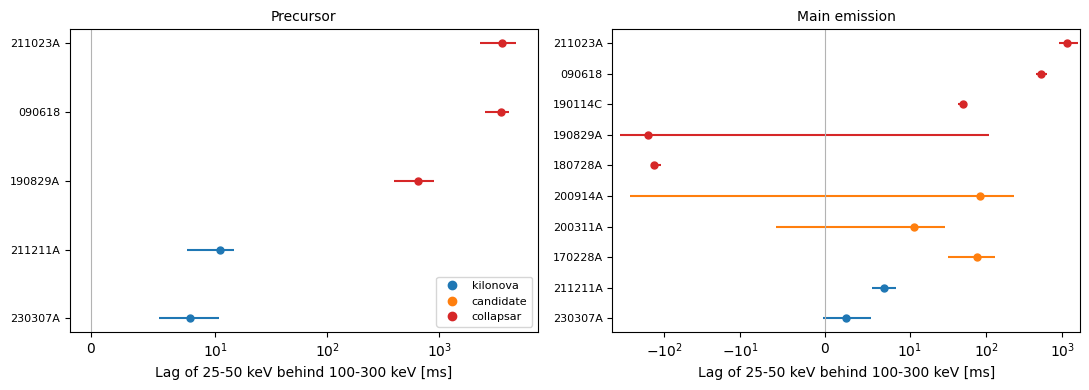

,burst,group,episode,duration_s,lag_ms,err_down,err_up,lag_over_duration
0,GRB230307A,kilonova,pre,0.180,7.9319,2.4448,2.9225,0.0441
1,GRB230307A,kilonova,main,5.600,2.5232,2.7938,2.9309,0.0005
2,GRB211211A,kilonova,pre,0.240,11.0034,3.2705,3.6097,0.0458
3,GRB211211A,kilonova,main,9.000,6.9719,1.4470,1.4373,0.0008
4,GRB170228A,candidate,main,15.552,76.1656,44.1656,53.3981,0.0049
5,GRB200311A,candidate,main,17.136,11.2708,17.0632,17.9146,0.0007
6,GRB200914A,candidate,main,17.872,82.8524,363.7271,147.4801,0.0046
7,GRB180728A,collapsar,main,6.864,-133.5504,14.8670,23.1607,-0.0195
8,GRB190829A,collapsar,pre,9.376,648.5989,257.1910,250.9145,0.0692
9,GRB190829A,collapsar,main,13.056,-161.7914,213.8878,270.5188,-0.0124


In [6]:
def row_of(table, key, burst, episode, duration):
    r = table.loc[key]
    return dict(burst=burst, group="kilonova", episode=episode, lag_ms=r.lag_ms, err_down=r.err_down, err_up=r.err_up, lag_cut_ms=r.lag_cut_ms, cut_down=r.cut_down, cut_up=r.cut_up, duration_s=duration)

known = [row_of(table_230, ("0 to 0.18", "n6 n8 na"), "GRB230307A", "pre", 0.18), row_of(table_230, ("7.9 to 13.5", "n6 n8 na"), "GRB230307A", "main", 5.6),
         row_of(table_211, ("precursor", "25-50 / 100-300"), "GRB211211A", "pre", 0.24), row_of(table_211, ("main", "25-50 / 100-300"), "GRB211211A", "main", 9.0)]
used = lags[lags.usable].copy()
used["duration_s"] = [float(w.split(" to ")[1]) - float(w.split(" to ")[0]) for w in used.window]
shown = pd.concat([pd.DataFrame(known), used[["burst", "group", "episode", "lag_ms", "err_down", "err_up", "lag_cut_ms", "cut_down", "cut_up", "duration_s"]]], ignore_index=True)
no_peak = shown.lag_ms.isna()
for name, cut_name in (("lag_ms", "lag_cut_ms"), ("err_down", "cut_down"), ("err_up", "cut_up")):
    shown.loc[no_peak, name] = shown.loc[no_peak, cut_name]
shown["lag_over_duration"] = 1e-3 * shown.lag_ms / shown.duration_s

COLOURS = {"kilonova": "tab:blue", "candidate": "tab:orange", "collapsar": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, episode in zip(axes, ("pre", "main")):
    part = shown[shown.episode == episode].reset_index(drop=True)
    for y, row in part.iterrows():
        ax.errorbar(row.lag_ms, y, xerr=[[row.err_down], [row.err_up]], fmt="o", color=COLOURS[row.group], ms=5)
    ax.set_yticks(range(len(part)))
    ax.set_yticklabels([b[3:] for b in part.burst], fontsize=8)
    ax.axvline(0.0, color="0.7", lw=0.8)
    ax.set_xscale("symlog", linthresh=10.0)
    ax.set_xlabel("Lag of 25-50 keV behind 100-300 keV [ms]")
    ax.set_title("Precursor" if episode == "pre" else "Main emission", fontsize=10)
for name, colour in COLOURS.items():
    axes[0].plot([], [], "o", color=colour, label=name)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "20_lags_by_class.png", dpi=200)
plt.show()
shown[["burst", "group", "episode", "duration_s", "lag_ms", "err_down", "err_up", "lag_over_duration"]].round(4)

**Precursors.** Three collapsars have a usable lag, and all are long: 650 (-260/+250) ms for 190829A, 3.6 (-1.0/+0.7) s for 090618 and 3.7 (-1.4/+1.2) s for 211023A. The kilonova precursors have 8 and 11 ms, so these lags are 60-460 times longer. But the precursors themselves are also 40-270 times longer. As a share of the window the lags are all similar: 0.04 and 0.05 for the kilonova bursts, and 0.07, 0.10 and 0.08 for the collapsars. A lag that grows with the width of the pulses is a known link. So here the lag doesn't say more than the duration already does.

The candidates can't settle it. Their precursors are hard, so they have few photons at 25-50 keV (2.6-4.7 sigma), and they miss the 5 sigma cut. For what they're worth, the values are 16 (-18/+101), 2 (-30/+49) and 28 (-30/+52) ms, all consistent with zero and with the same share of their 0.2-0.7 s. 180728A's precursor has too little above 100 keV (3.6 sigma), and 190114C's has nothing in the low band.

**Main emission.** This is the classic comparison. The kilonova bursts have 2.5 (-2.8/+2.9) and 7.0 (-1.4/+1.4) ms. The candidates have 11 (-17/+18), 76 (-44/+53) and 83 (-364/+148) ms, all within 2 sigma of zero, as Tan et al. find, though two have large errors. Three collapsars are positive and significant: 49 (-6/+6) ms for 190114C, 530 (-82/+93) ms for 090618 and 1.16 (-0.27/+0.44) s for 211023A. So the classic picture holds for most of them, and here the lengths are similar enough (6-70 s) that it isn't just duration: the share of the window is below 0.001 for the kilonova bursts and 200311A, 0.005 for the other two candidates and 0.005-0.02 for those collapsars.

Two collapsars don't fit. 180728A is significantly negative, -134 (-15/+23) ms, and 190829A is consistent with zero, -160 (-210/+270) ms. Both are soft, with E_p about 90 and 10 keV, so these bands sit at or above their peak. 180728A's main emission also has two peaks close together, at about 10.7 and 11.5 s, which may be what the CCF is aligning. I haven't looked into it further.

## 5. What this says

- **The method matters in short windows.** Cutting both light curves at the window loses about 40% of a lag in a window as short as a precursor, and the shift test with real photons shows it. Letting the low band run past the window fixes that.
- **The published values come back:** Dichiara et al.'s four, done their way, and Troja et al.'s 16 ms for GRB 211211A's precursor from a different instrument.
- **GRB 230307A's precursor may have a small positive lag,** 7.9 (-2.4/+2.9) ms instead of 'consistent with zero', similar to GRB 211211A's 11 ms in the same bands.
- **Precursor lags don't add to the duration in this sample.** Collapsars' are tens to hundreds of times longer, and so are their precursors.
- **The candidates' precursors are too faint at 25-50 keV for a lag.** The hard spectrum that makes E_p hard to pin down also leaves few low-energy photons. Bands higher up would be worth trying, say 50-100 against 100-300 keV.
- **In the main emission the classic separation mostly holds,** with two soft collapsars as exceptions, which is no more than the literature already says. So it supports the candidates being like the kilonova bursts, but it doesn't confirm it, since the lag is part of what's usually used to choose such candidates.